# Notebook 03 — Data Cleaning + EDA + Structured Dataset Prep

Ye notebook: (1) dono datasets merge karti hai, (2) cleaning + EDA karti hai, (3) end mein **Cox model ke liye required 2 columns** (`is_disposed`, `duration_days`) add karke final **`structured_dataset.csv`** save karti hai — jo Notebook 04 (Cox Proportional Hazards) seedha use karega.

**Is notebook mein koi model, encoding, ya priority score nahi hai** — sirf cleaning, EDA, aur ye 2 prep-columns.

## Step 1 — Load + merge quantitative (disposal-time) + qualitative (text) datasets

In [1]:
import pandas as pd
import numpy as np

base = pd.read_csv(r'E:\Projects\Judicial AI system with drift detection\data\processed\filtered_low_severity_cases.csv')
disposal = pd.read_csv(r'E:\Projects\Judicial AI system with drift detection\data\processed\bail_cases_with_disposal_time.csv')[['case_id','disposal_days','estimation_method']]

df = base.merge(disposal, on='case_id', how='left')

print("Base shape:", base.shape, "| Disposal shape:", disposal.shape, "| Merged shape:", df.shape)
print("Missing disposal_days after merge:", df['disposal_days'].isna().sum())
df.info()


Base shape: (365, 25) | Disposal shape: (365, 3) | Merged shape: (365, 27)
Missing disposal_days after merge: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   case_id                      365 non-null    int64 
 1   case_title                   365 non-null    object
 2   court                        365 non-null    object
 3   date                         365 non-null    object
 4   judge                        365 non-null    object
 5   ipc_sections                 365 non-null    object
 6   bail_type                    365 non-null    object
 7   bail_cancellation_case       365 non-null    bool  
 8   landmark_case                365 non-null    bool  
 9   accused_name                 365 non-null    object
 10  accused_gender               365 non-null    object
 11  prior_cases                  365 non-

## Step 2 — Quick EDA

In [2]:
print("=== Bail Outcome Distribution ===")
print(df['bail_outcome'].value_counts())

print("\n=== Date Range ===")
df['date'] = pd.to_datetime(df['date'])
print("Earliest:", df['date'].min())
print("Latest:", df['date'].max())

print("\n=== Prior Cases ===")
print(df['prior_cases'].value_counts())

print("\n=== Accused Gender ===")
print(df['accused_gender'].value_counts())

print("\n=== Region ===")
print(df['region'].value_counts())

print("\n=== Disposal Days (new) ===")
print(df['disposal_days'].describe())
print("\n=== Estimation Method (new) ===")
print(df['estimation_method'].value_counts())


=== Bail Outcome Distribution ===
bail_outcome
Granted     226
Rejected    139
Name: count, dtype: int64

=== Date Range ===
Earliest: 1985-12-10 00:00:00
Latest: 2025-06-02 00:00:00

=== Prior Cases ===
prior_cases
Unknown    194
Yes        132
No          39
Name: count, dtype: int64

=== Accused Gender ===
accused_gender
Male      340
Female     25
Name: count, dtype: int64

=== Region ===
region
Bihar                 47
Punjab                45
Jharkhand             44
Madhya Pradesh        33
Delhi                 33
Uttar Pradesh         32
Karnataka             26
Maharashtra           22
Kerala                11
Gujarat               11
Haryana               11
Himachal Pradesh       8
Chhattisgarh           8
West Bengal            7
Rajasthan              7
Odisha                 5
Tamil Nadu             3
Andhra Pradesh         2
Telangana              2
Assam                  2
Jammu & Kashmir        1
Manipur                1
Puducherry             1
Chandigarh            

## Step 3 — Region cleanup

In [3]:
# 'Punjab and Haryana' ko 'Punjab' mein merge kar rahe hain
df['region'] = df['region'].replace('Punjab and Haryana', 'Punjab')
print(df['region'].value_counts())


region
Bihar               47
Punjab              46
Jharkhand           44
Delhi               33
Madhya Pradesh      33
Uttar Pradesh       32
Karnataka           26
Maharashtra         22
Kerala              11
Haryana             11
Gujarat             11
Chhattisgarh         8
Himachal Pradesh     8
Rajasthan            7
West Bengal          7
Odisha               5
Tamil Nadu           3
Assam                2
Andhra Pradesh       2
Telangana            2
Manipur              1
Chandigarh           1
Jammu & Kashmir      1
Uttarakhand          1
Puducherry           1
Name: count, dtype: int64


## Step 4 — Extract year from date

In [4]:
df['year'] = df['date'].dt.year
print(df[['date','year']].head())
print("\nYear range:", df['year'].min(), "to", df['year'].max())


        date  year
0 2008-08-05  2008
1 2020-11-27  2020
2 2019-03-01  2019
3 2024-08-07  2024
4 2024-04-05  2024

Year range: 1985 to 2025


## Step 5 — Baseline vs monitoring period flag
(Future drift-detection notebook ke liye useful.)

In [5]:
df['period'] = df['year'].apply(lambda y: 'baseline' if y < 2020 else 'monitoring')
print(df['period'].value_counts())


period
monitoring    263
baseline      102
Name: count, dtype: int64


## Step 6 — Drop unused bias_flag, derive has_special_law

In [6]:
df = df.drop(columns=['bias_flag'])
df['has_special_law'] = df['special_laws'].notna()
print(df['has_special_law'].value_counts())


has_special_law
False    346
True      19
Name: count, dtype: int64


## Step 7 — EDA plot: cases per year

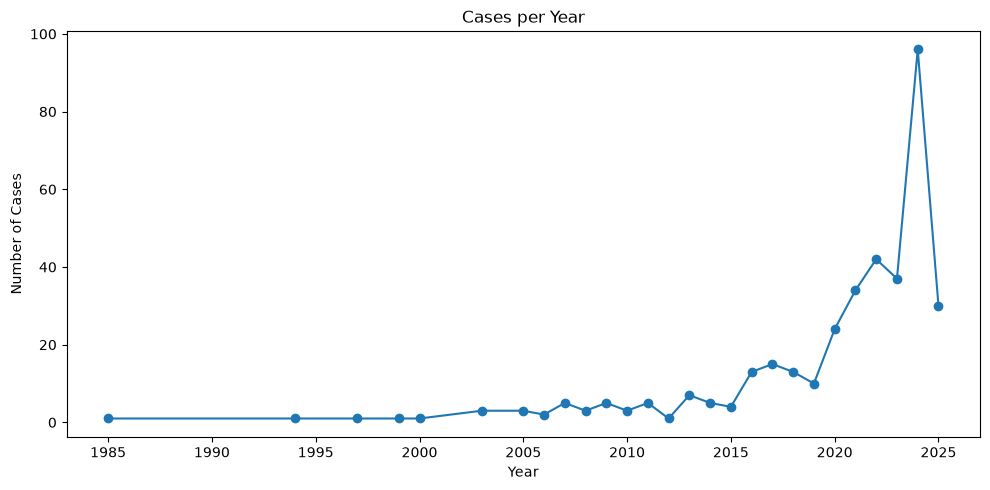

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt

df['year'].value_counts().sort_index().plot(kind='line', marker='o', figsize=(10,5))
plt.title('Cases per Year')
plt.xlabel('Year'); plt.ylabel('Number of Cases')
plt.tight_layout()
plt.show()


## Step 8 — EDA plot: bail outcome by prior cases

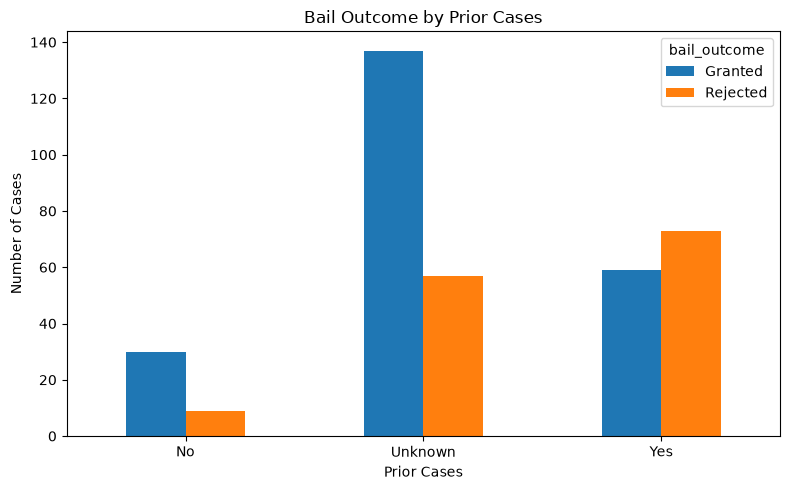

In [8]:
pd.crosstab(df['prior_cases'], df['bail_outcome']).plot(kind='bar', figsize=(8,5))
plt.title('Bail Outcome by Prior Cases')
plt.xlabel('Prior Cases'); plt.ylabel('Number of Cases')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Step 9 — EDA plot: disposal_days by crime_type

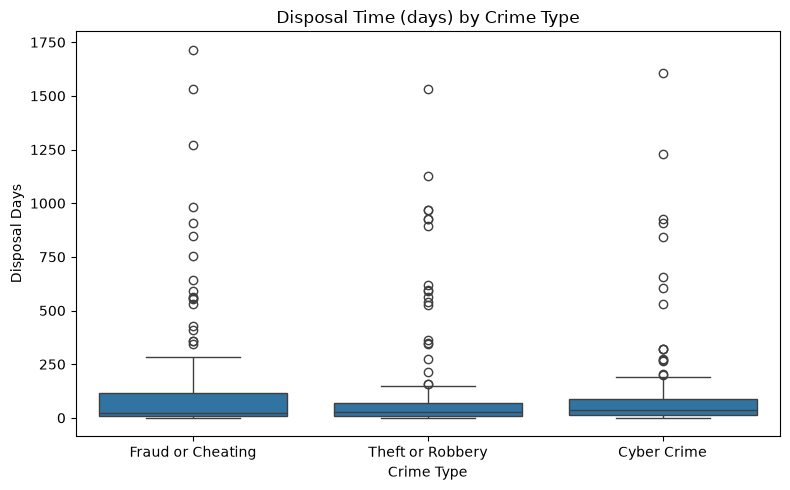

crime_type
Cyber Crime          35.0
Fraud or Cheating    25.0
Theft or Robbery     29.5
Name: disposal_days, dtype: float64


In [9]:
# NEW: disposal_days distribution by crime_type -- now possible since we merged it in
import seaborn as sns
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='crime_type', y='disposal_days')
plt.title('Disposal Time (days) by Crime Type')
plt.xlabel('Crime Type'); plt.ylabel('Disposal Days')
plt.tight_layout()
plt.show()
print(df.groupby('crime_type')['disposal_days'].median())


## Step 10 — Court distribution check

In [10]:
print("Unique courts:", df['court'].nunique())
print(df['court'].value_counts().head(15))


Unique courts: 45
court
Punjab and Haryana High Court                57
Patna High Court                             47
Jharkhand High Court                         44
Delhi High Court                             31
Allahabad High Court                         28
Madhya Pradesh High Court                    14
Bombay High Court                            14
Karnataka High Court                         13
Kerala High Court                            11
Supreme Court of India                       11
Gujarat High Court                           11
Madhya Pradesh High Court, Jabalpur Bench    10
Himachal Pradesh High Court                   8
Calcutta High Court                           7
Karnataka High Court, Dharwad Bench           5
Name: count, dtype: int64


## Step 11 — Group rare regions (<5 cases) into 'Other'

In [11]:
# Region ko group karo - jin regions mein 5 se kam cases hain unhe 'Other' mein daalo
region_counts = df['region'].value_counts()
rare_regions = region_counts[region_counts < 5].index
df['region_grouped'] = df['region'].apply(lambda r: 'Other' if r in rare_regions else r)
print(df['region_grouped'].value_counts())


region_grouped
Bihar               47
Punjab              46
Jharkhand           44
Delhi               33
Madhya Pradesh      33
Uttar Pradesh       32
Karnataka           26
Maharashtra         22
Other               14
Kerala              11
Gujarat             11
Haryana             11
Himachal Pradesh     8
Chhattisgarh         8
West Bengal          7
Rajasthan            7
Odisha               5
Name: count, dtype: int64


## Step 12 — Add survival-analysis columns (for Cox model, Notebook 04)
Koi naya merge nahi — `df` already merged hai (Step 1 se). Ye sirf 2 derived columns hain jo Cox model expect karta hai:
- **`is_disposed`**: event indicator. Hamare paas jo bhi cases hain, unka outcome documented/resolved hai (koi pending/censored case nahi), isliye sab `1`.
- **`duration_days`**: `disposal_days` ko numeric format mein — ye Cox model ka time-to-event variable banega.

In [12]:
# Survival-analysis ke liye required columns add kar rahe hain (Cox model, Notebook 04 ke liye).
# Koi naya merge nahi -- df already merged hai (Step 1). Koi model bhi nahi -- sirf
# 2 derived columns jo Cox model ko chahiye:

# 1) Event indicator: hamare paas jo bhi cases hain, unka outcome already documented/resolved
#    hai (koi abhi-pending/censored case nahi hai is dataset mein), isliye sab '1' (disposed).
df['is_disposed'] = 1

# 2) Duration column, numeric format mein (Cox model ka "time-to-event" variable)
df['duration_days'] = pd.to_numeric(df['disposal_days'], errors='coerce')
df = df.dropna(subset=['duration_days'])

print(f"Rows with valid duration: {len(df)}")
print(df[['case_id', 'crime_type', 'region', 'duration_days', 'is_disposed']].head())


Rows with valid duration: 365
   case_id         crime_type          region  duration_days  is_disposed
0        3  Fraud or Cheating          Kerala             33            1
1       63   Theft or Robbery  Madhya Pradesh             22            1
2       64  Fraud or Cheating     Maharashtra             26            1
3       72  Fraud or Cheating           Delhi             10            1
4       83  Fraud or Cheating         Gujarat             26            1


## Step 13 — Save final structured dataset
Ye file ab **Notebook 04 (Cox model)** seedha load karega — is se aage koi extra merging nahi karni padegi.

In [13]:
# Final structured dataset -- ye ab Notebook 04 (Cox model) seedha isse load karega.
df.to_csv(r'E:\Projects\Judicial AI system with drift detection\data\processed/structured_dataset.csv', index=False)
print("Saved -> ../data/processed/structured_dataset.csv", df.shape)


Saved -> ../data/processed/structured_dataset.csv (365, 32)
